# 03 – Line simulation and energy
Simulate the 10-operation T-shirt line for each scenario, then convert machine run time into kWh and CO₂ per garment.

### Setup
Load the operations table and parameters, then build the two operator allocations:
- **Takt time** = available time / required output = $480 / 800 = 0.60$ min per garment.
- **Scenario A**: one operator per operation (10 operators).
- **Scenario B**: operators per operation = $\lceil \text{SMV} / \text{takt} \rceil$. Ops 6 (0.80) and 7 (0.90) need $\lceil 1.33 \rceil = \lceil 1.5 \rceil = 2$; the rest need 1 → 12 operators.

In [2]:
import sys
sys.path.append("..")          # let the notebook import from src/

import matplotlib.pyplot as plt
import pandas as pd

from src.inputs import load_operations, load_parameters
from src.balancing import takt_time, theoretical_operators, allocate_one_each, allocate_by_takt
from src.simulation import simulate_line, run_replications, mean_ci95
from src.energy import shift_energy_kwh, co2_kg

ops = load_operations()
params = load_parameters()
line, var, energy = params["line"], params["variability"], params["energy"]

takt = takt_time(line["shift_min"], line["target_pcs_per_day"])
alloc = {"A": allocate_one_each(ops),
         "B": allocate_by_takt(theoretical_operators(ops, takt))}

### Output vs. variability
Run A and B at variability 0, ±15% and ±25%, 10 seeds each, and report mean/min/max garments per shift.

Expected from the slowest station (cycle time = max of SMV / operators):
- A: bottleneck op 7, $480 / 0.90 \approx 533$
- B: cycle 0.60, $480 / 0.60 = 800$

Simulated values are a bit lower because the line starts empty (no warm-up here) and random variation causes small losses.

In [3]:
rows = []
for name, operators in alloc.items():
    for variability in [0.0, 0.15, 0.25]:
        outputs = [simulate_line(ops, operators, variability, seed)["output"]
                   for seed in range(1, 11)]
        rows.append({"scenario": name, "variability": variability,
                     "mean_output": sum(outputs) / len(outputs),
                     "min": min(outputs), "max": max(outputs)})
print(pd.DataFrame(rows).to_string(index=False))

scenario  variability  mean_output  min  max
       A         0.00        529.0  529  529
       A         0.15        528.2  527  530
       A         0.25        528.0  526  533
       B         0.00        793.0  793  793
       B         0.15        792.7  789  797
       B         0.25        789.5  784  792


### Utilization per operation
For one run (±15%, seed 1):

$$\text{utilization} = \frac{\text{busy minutes}}{\text{operators at the op} \times 480}$$

In A, op 7 is near 1.0 (bottleneck) while the others wait. In B, the load is more even; ops 5 and 10 (SMV = takt) are near 1.0.

In [4]:
util = {}
for name, operators in alloc.items():
    busy = pd.Series(simulate_line(ops, operators, 0.15, seed=1)["busy_min"])
    util[name] = (busy / (operators * line["shift_min"])).round(2)
pd.DataFrame(util).assign(smv=ops["smv_min"])

,A,B,smv
1,0.49,0.71,0.40
2,0.59,0.87,0.50
3,0.53,0.77,0.45
4,0.63,0.93,0.55
5,0.69,1.00,0.60
6,0.90,0.67,0.80
7,0.99,0.75,0.90
8,0.60,0.92,0.55
9,0.28,0.43,0.25
10,0.66,0.99,0.60


### WIP and rack contents
For one run of each scenario, show output, mean WIP (pieces on all racks, sampled each minute) and WIP per operator = mean WIP / total operators.

`racks_end` shows pieces left on each operation's output rack (capacity 10). Full racks (10) sit before the bottleneck; empty racks come after it.

In [5]:
for name, operators in alloc.items():
    r = simulate_line(ops, operators, 0.15, seed=1)
    print(name, "| output:", r["output"], "| mean WIP:", round(r["mean_wip"], 1),
          "| WIP per operator:", round(r["mean_wip"] / operators.sum(), 1))
    print("   racks at end of shift:", r["racks_end"])

A | output: 527 | mean WIP: 67.4 | WIP per operator: 6.7
   racks at end of shift: {1: 10, 2: 10, 3: 10, 4: 10, 5: 10, 6: 10, 7: 0, 8: 0, 9: 10, 10: 0}
B | output: 794 | mean WIP: 49.1 | WIP per operator: 4.1
   racks at end of shift: {1: 10, 2: 10, 3: 10, 4: 10, 5: 0, 6: 0, 7: 0, 8: 4, 9: 10, 10: 0}


### Rack size: output vs. WIP and lead time
Scenario B with rack sizes 1–20 (10 seeds each). Lead time comes from **Little's Law**:

$$L = \lambda W \quad\Rightarrow\quad W = \frac{L}{\lambda}$$

- $L$ = mean WIP (pieces)
- $\lambda$ = throughput = output / 480 (pieces per minute)
- $W$ = average time a piece spends in the line (min)

Bigger racks hardly increase output but raise WIP and lead time roughly in proportion.

In [6]:
rows = []
for rack in [1, 2, 3, 5, 10, 20]:
    runs = [simulate_line(ops, alloc["B"], 0.15, seed, buffer_size=rack) for seed in range(1, 11)]
    rows.append({"rack_size": rack,
                 "mean_output": sum(r["output"] for r in runs) / len(runs),
                 "mean_wip": sum(r["mean_wip"] for r in runs) / len(runs)})
res = pd.DataFrame(rows)
res["wip_per_operator"] = res["mean_wip"] / alloc["B"].sum()
res["lead_time_min"] = res["mean_wip"] / (res["mean_output"] / line["shift_min"])  # Little's Law
res.round(1)

,rack_size,mean_output,mean_wip,wip_per_operator,lead_time_min
0,1,790.3,6.4,0.5,3.9
1,2,791.5,12.6,1.0,7.6
2,3,791.9,17.1,1.4,10.4
3,5,792.0,26.7,2.2,16.2
4,10,792.7,48.9,4.1,29.6
5,20,792.9,88.9,7.4,53.8


### 30 replications with 95% CI
Define the scenarios (A, B, D) and run each one 30 times (seeds 1–30). `warmup=60` runs the line for 60 min first and ignores that period, so results describe a filled line rather than start-up. These runs are stored in `runs` and reused by the cells below, so the simulation only happens once.

Each value is shown as mean ± half-width:

$$\text{half-width} = t_{0.975,\,29} \times \frac{s}{\sqrt{n}} = 2.045 \times \frac{s}{\sqrt{30}}$$

where $s$ is the sample standard deviation. Efficiency = busy minutes / (operators × 480) and should match the balancing calculation (A ≈ 0.62, B ≈ 0.78).

In [7]:
# scenario: (operators, variability)
scenarios = {"A": (alloc["A"], var["base_pct"]),
             "B": (alloc["B"], var["base_pct"]),
             "D": (alloc["B"], var["high_pct"])}

# 30 replications per scenario, run once here and reused by the cells below
runs = {name: run_replications(ops, operators, variability, warmup=60)
        for name, (operators, variability) in scenarios.items()}

table = []
for name in ["A", "B"]:
    row = {"scenario": name}
    for col, decimals in [("output", 1), ("mean_wip", 1), ("efficiency", 3)]:
        mean, half = mean_ci95(runs[name][col].tolist())
        row[col] = f"{mean:.{decimals}f} ± {half:.{decimals}f}"
    table.append(row)
pd.DataFrame(table)

,scenario,output,mean_wip,efficiency
0,A,532.9 ± 0.7,69.9 ± 0.0,0.623 ± 0.001
1,B,799.3 ± 0.8,52.1 ± 0.4,0.780 ± 0.001


### Operational results per scenario
- **A**: one operator per op, ±15%
- **B**: SMV/takt allocation, ±15%
- **D**: B with high variability (±25%)

For each of the 30 runs: WIP per operator = mean WIP / operators, and lead time = mean WIP / (output / 480) (Little's Law). Then mean and CI half-width over the 30 runs. Saved to `results/scenario_results_ops.csv`.

In [8]:
rows = []
for name, (operators, variability) in scenarios.items():
    reps = runs[name].copy()
    reps["wip_per_operator"] = reps["mean_wip"] / operators.sum()
    reps["lead_time_min"] = reps["mean_wip"] / (reps["output"] / line["shift_min"])  # Little's Law

    row = {"scenario": name, "operators": int(operators.sum()), "variability": variability}
    for col in ["output", "efficiency", "wip_per_operator", "lead_time_min"]:
        mean, half = mean_ci95(reps[col].tolist())
        row[col] = round(mean, 3)
        row[col + "_ci"] = round(half, 3)
    rows.append(row)

results = pd.DataFrame(rows)
results.to_csv("../results/scenario_results_ops.csv", index=False)
results

,scenario,operators,variability,output,output_ci,efficiency,efficiency_ci,wip_per_operator,wip_per_operator_ci,lead_time_min,lead_time_min_ci
0,A,10,0.15,532.900,0.743,0.623,0.001,6.994,0.001,62.999,0.087
1,B,12,0.15,799.300,0.791,0.780,0.001,4.344,0.037,31.301,0.275
2,D,12,0.25,797.533,1.068,0.780,0.001,4.471,0.064,32.292,0.473


### Energy and CO₂ per garment
Adds **C** = B with servo motors instead of clutch motors. Only machine operations count (op 10 is manual).

Energy for one shift (`src/energy.py`):

$$\text{stitch min} = f \times \text{machine busy min}$$
$$\text{idle min} = n_{\text{machines}} \times 480 - \text{stitch min}$$
$$\text{kWh} = \frac{P_{\text{run}} \times \text{stitch min} + P_{\text{idle}} \times \text{idle min}}{60}$$

- $f$ = 0.40, share of busy time the motor is actually sewing.
- $P_{\text{run}}$ = 0.30 kW; $P_{\text{idle}}$ = 0.30 kW (clutch, runs constantly) or 0.02 kW (servo).
- Divide by 60 to convert kW·min to kWh.

Per garment: kWh / output, and $\text{g CO₂} = \text{kWh} \times 0.62 \times 1000$ (0.62 kg CO₂/kWh grid factor for Bangladesh). Saved to `results/scenario_results_energy.csv`.

In [9]:
machines = ops.index[ops["machine"] != "Manual"]     # op 10 is manual, no motor

# scenario: (operators, which simulation run to use, motor type)
energy_scenarios = {"A": (alloc["A"], "A", "clutch"),
                    "B": (alloc["B"], "B", "clutch"),
                    "C": (alloc["B"], "B", "servo"),     # line B with servo motors
                    "D": (alloc["B"], "D", "clutch")}

rows = []
for name, (operators, run, motor) in energy_scenarios.items():
    reps = runs[run].copy()
    n_machines = int(operators[machines].sum())
    kwh = shift_energy_kwh(n_machines, reps["machine_busy_min"], line["shift_min"], energy, motor)
    reps["kwh_per_garment"] = kwh / reps["output"]
    reps["g_co2_per_garment"] = co2_kg(reps["kwh_per_garment"], energy) * 1000

    row = {"scenario": name, "motor": motor}
    for col in ["output", "kwh_per_garment", "g_co2_per_garment"]:
        mean, half = mean_ci95(reps[col].tolist())
        row[col] = round(mean, 4)
        row[col + "_ci"] = round(half, 4)
    rows.append(row)

energy_results = pd.DataFrame(rows)
energy_results.to_csv("../results/scenario_results_energy.csv", index=False)
energy_results

,scenario,motor,output,output_ci,kwh_per_garment,kwh_per_garment_ci,g_co2_per_garment,g_co2_per_garment_ci
0,A,clutch,532.9000,0.7425,0.0405,0.0001,25.1308,0.0350
1,B,clutch,799.3000,0.7914,0.0330,0.0000,20.4781,0.0203
2,C,servo,799.3000,0.7914,0.0116,0.0000,7.1773,0.0071
3,D,clutch,797.5333,1.0684,0.0331,0.0000,20.5235,0.0275


### Chart: CO₂ per garment
Bar chart of g CO₂ per T-shirt for A–D, with error bars = 95% CI half-width. Saved to `results/figures/co2_per_garment.png`.

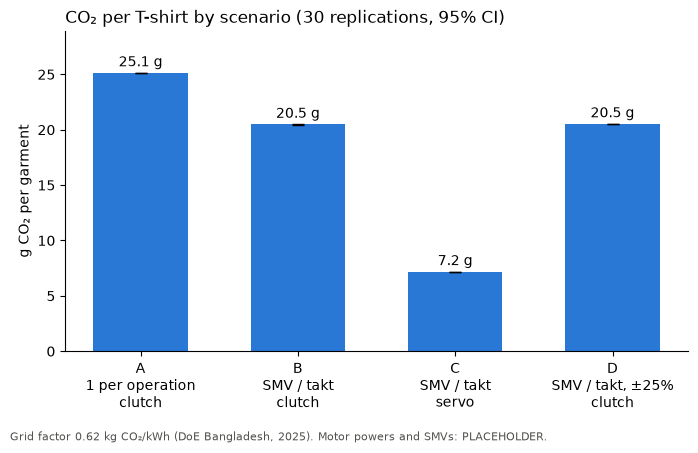

In [10]:
energy_results = pd.read_csv("../results/scenario_results_energy.csv")
labels = {"A": "A\n1 per operation\nclutch", "B": "B\nSMV / takt\nclutch",
          "C": "C\nSMV / takt\nservo", "D": "D\nSMV / takt, ±25%\nclutch"}
x = [labels[s] for s in energy_results["scenario"]]
y = energy_results["g_co2_per_garment"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x, y, yerr=energy_results["g_co2_per_garment_ci"], width=0.6,
       color="#2a78d6", capsize=4)
for xi, yi in zip(x, y):
    ax.text(xi, yi + 0.6, f"{yi:.1f} g", ha="center")
ax.set_ylim(0, y.max() * 1.15)                      # headroom for the labels
ax.set_ylabel("g CO₂ per garment")
ax.set_title("CO₂ per T-shirt by scenario (30 replications, 95% CI)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Grid factor 0.62 kg CO₂/kWh (DoE Bangladesh, 2025). "
         "Motor powers and SMVs: PLACEHOLDER.", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("../results/figures/co2_per_garment.png", dpi=150)

### Chart: output and lead time
Two panels for A, B and D: garments per shift (dashed line = 800 target) and lead time from Little's Law, each with 95% CI error bars. Saved to `results/figures/output_and_lead_time.png`.

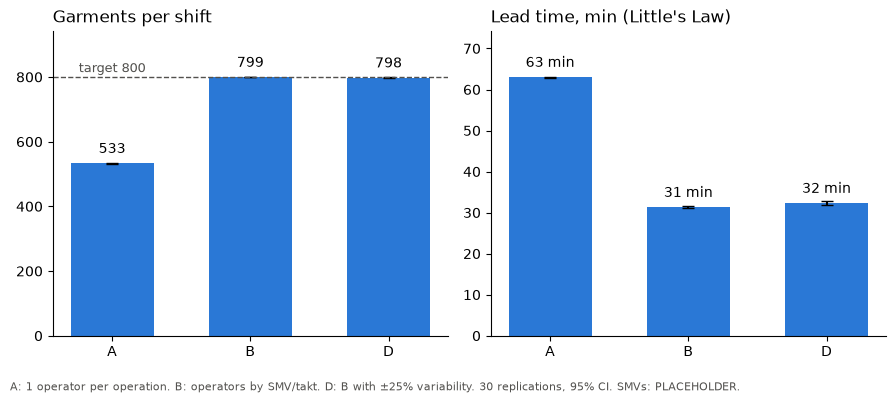

In [11]:
ops_results = pd.read_csv("../results/scenario_results_ops.csv")
names = ops_results["scenario"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
panels = [(ax1, "output", "Garments per shift", "{:.0f}"),
          (ax2, "lead_time_min", "Lead time, min (Little's Law)", "{:.0f} min")]
for ax, col, title, fmt in panels:
    vals = ops_results[col]
    ax.bar(names, vals, yerr=ops_results[col + "_ci"], width=0.6, color="#2a78d6", capsize=4)
    for name, v in zip(names, vals):
        ax.text(name, v + vals.max() * 0.04, fmt.format(v), ha="center")
    ax.set_ylim(0, vals.max() * 1.18)
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)

ax1.axhline(800, color="#52514e", linestyle="--", linewidth=1)     # daily target
ax1.text(0, 815, "target 800", color="#52514e", fontsize=9, ha="center")
fig.text(0.01, 0.01, "A: 1 operator per operation. B: operators by SMV/takt. "
         "D: B with ±25% variability. 30 replications, 95% CI. SMVs: PLACEHOLDER.",
         fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("../results/figures/output_and_lead_time.png", dpi=150)

### Sensitivity of CO₂ to energy assumptions
The motor powers and stitching fraction are placeholders, so test how much the conclusions depend on them.
- `g_co2()` uses the mean machine busy time and mean output of the A or B runs from above.
- Change **one** parameter at a time and recompute g CO₂ per garment for A, B and C. When `running_power_kw` changes, clutch idle power changes with it (a clutch motor runs at full power when idle).
- Relative change between scenarios:

$$\text{A→B \%} = 100 \times \frac{B - A}{A}, \qquad \text{B→C \%} = 100 \times \frac{C - B}{B}$$

If the sign and rough size of these percentages stay the same across values, the conclusion is robust. Saved to `results/sensitivity_energy.csv`.

In [12]:
def g_co2(name: str, motor: str, e: dict) -> float:
    """Mean g CO2 per garment for simulation run `name`, motor type and energy parameters e."""
    reps = runs[name]
    n_machines = int(alloc[name][machines].sum())
    kwh = shift_energy_kwh(n_machines, reps["machine_busy_min"].mean(), line["shift_min"], e, motor)
    return co2_kg(kwh, e) * 1000 / reps["output"].mean()


tests = {"running_power_kw": [0.20, 0.30, 0.40],
         "clutch_idle_power_kw": [0.15, 0.30],
         "servo_idle_power_kw": [0.01, 0.02, 0.05],
         "stitching_fraction": [0.30, 0.40, 0.50]}

rows = []
for param, values in tests.items():
    for value in values:
        e = {**energy, param: value}                # copy, change ONE parameter
        if param == "running_power_kw":
            e["clutch_idle_power_kw"] = value       # a clutch motor idles at running power
        a, b, c = g_co2("A", "clutch", e), g_co2("B", "clutch", e), g_co2("B", "servo", e)
        rows.append({"parameter": param, "value": value, "A_g": a, "B_g": b, "C_g": c,
                     "A_to_B_%": 100 * (b - a) / a, "B_to_C_%": 100 * (c - b) / b})

sens = pd.DataFrame(rows).round({"A_g": 1, "B_g": 1, "C_g": 1, "A_to_B_%": 1, "B_to_C_%": 1})
sens.to_csv("../results/sensitivity_energy.csv", index=False)
sens

,parameter,value,A_g,B_g,C_g,A_to_B_%,B_to_C_%
0,running_power_kw,0.20,16.8,13.7,5.1,-18.5,-62.6
1,running_power_kw,0.30,25.1,20.5,7.2,-18.5,-65.0
2,running_power_kw,0.40,33.5,27.3,9.3,-18.5,-66.1
3,clutch_idle_power_kw,0.15,15.7,13.4,7.2,-14.8,-46.2
4,clutch_idle_power_kw,0.30,25.1,20.5,7.2,-18.5,-65.0
5,servo_idle_power_kw,0.01,25.1,20.5,6.7,-18.5,-67.3
6,servo_idle_power_kw,0.02,25.1,20.5,7.2,-18.5,-65.0
7,servo_idle_power_kw,0.05,25.1,20.5,8.6,-18.5,-58.0
8,stitching_fraction,0.30,25.1,20.5,5.7,-18.5,-72.0
9,stitching_fraction,0.40,25.1,20.5,7.2,-18.5,-65.0
